# Issues with real world data

### Outliers: data points which are outside expected range are called outliers. We can safely remove these data points. 

### Bias: Bias refers to a tendency to select certain types of values more frequently than others in a way that mispresents the underlying population. 

### Real world data always has issues. We can overcome these issues by:
<li>Checking for missing data or badly recorded data</li>
<li>Considering removing obvious outliers</li>
<li>Checking for biased raw data amd considering their options to fix the bias, if found.</li>
<li>Examining real world factors that might affect data analysis and try to remove impacted data if data size is large enough.</li>



         Name  StudyHours  Grade   Pass
0         Dan       10.00   50.0  False
1       Joann       11.50   50.0  False
2       Pedro        9.00   47.0  False
3       Rosie       16.00   97.0   True
4       Ethan        9.25   49.0  False
5       Vicky        1.00    3.0  False
6    Frederic       11.50   53.0  False
7      Jimmie        9.00   42.0  False
8      Rhonda        8.50   26.0  False
9    Giovanni       14.50   74.0   True
10  Francesca       15.50   82.0   True
11      Rajab       13.75   62.0   True
12    Naiyana        9.00   37.0  False
13       Kian        8.00   15.0  False
14      Jenny       15.50   70.0   True
15     Jakeem        8.00   27.0  False
16     Helena        9.00   36.0  False
17      Ismat        6.00   35.0  False
18      Anila       10.00   48.0  False
19       Skye       12.00   52.0  False
20     Daniel       12.50   63.0   True
21      Aisha       12.00   64.0   True
Min: 3.0
Max: 97.0
Mean: 49.18181818181818
Median: 49.5
Mode: 50.0


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_9402/3773329807.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


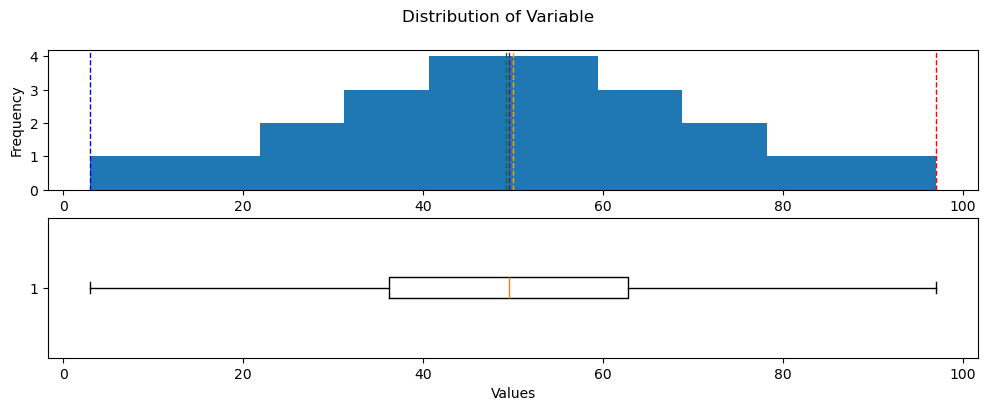

In [11]:
import pandas as pd

from matplotlib import pyplot as plt

df_students = pd.read_csv('grades.csv', delimiter=',', header='infer')
df_students.head()
df_students = df_students.dropna(axis=0, how='any')  # drop rows with any NaN values

passes = pd.Series(df_students.Grade >= 60)

df_students = pd.concat([df_students, passes.rename('Pass')], axis=1)
print(df_students)

def show_distribution(var_data):
    min_val = var_data.min()
    max_val = var_data.max()
    mean_val = var_data.mean()
    median_val = var_data.median()
    mode_val = var_data.mode()[0]

    print(f'Min: {min_val}\nMax: {max_val}\nMean: {mean_val}\nMedian: {median_val}\nMode: {mode_val}')

    fig, ax = plt.subplots(2, 1, figsize=(12, 4))

    ax[0].hist(var_data)
    ax[0].set_ylabel('Frequency')

    ax[0].axvline(x=min_val, color='blue', linestyle='dashed', linewidth=1, label='Min')
    ax[0].axvline(x=max_val, color='red', linestyle='dashed', linewidth=1, label='Max')
    ax[0].axvline(x=mean_val, color='green', linestyle='dashed', linewidth=1, label='Mean')
    ax[0].axvline(x=median_val, color='purple', linestyle='dashed', linewidth=1, label='Median')
    ax[0].axvline(x=mode_val, color='orange', linestyle='dashed', linewidth=1, label='Mode')

    ax[1].boxplot(var_data, vert=False)
    ax[1].set_xlabel('Values')

    fig.suptitle('Distribution of Variable')
    fig.show()

show_distribution(df_students['Grade'])



Min: 6.0
Max: 16.0
Mean: 10.976190476190476
Median: 10.0
Mode: 9.0


/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_9402/3773329807.py:38: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


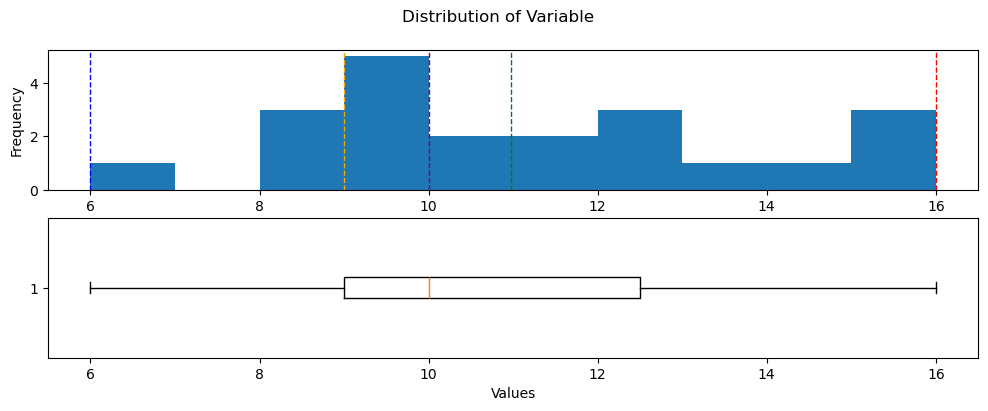

In [12]:
col = df_students[df_students.StudyHours > 1].StudyHours
show_distribution(col)

/var/folders/lz/9ztyyq913n1_6xkj9g8_jlg40000gn/T/ipykernel_9402/3000100686.py:11: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


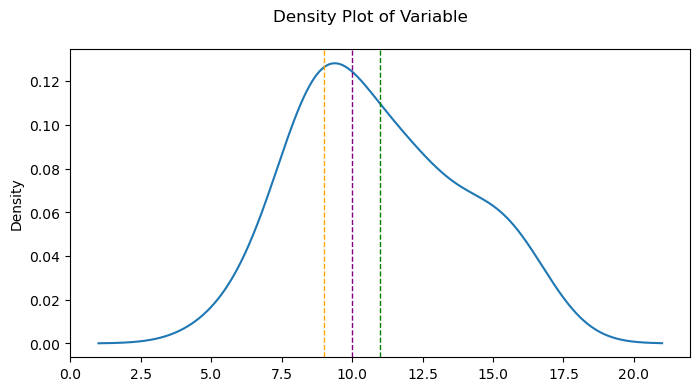

In [19]:
def show_density(var_data):
    fig, ax = plt.subplots(figsize=(8, 4))

    var_data.plot.density()
    ax.axvline(x=var_data.mean(), color='green', linestyle='dashed', linewidth=1, label='Mean')
    ax.axvline(x=var_data.median(), color='purple', linestyle='dashed', linewidth=1, label='Median')
    ax.axvline(x=var_data.mode()[0], color='orange', linestyle='dashed', linewidth=1, label='Mode')
    ax.set_ylabel('Density')

    fig.suptitle('Density Plot of Variable')
    fig.show()

show_density(col)

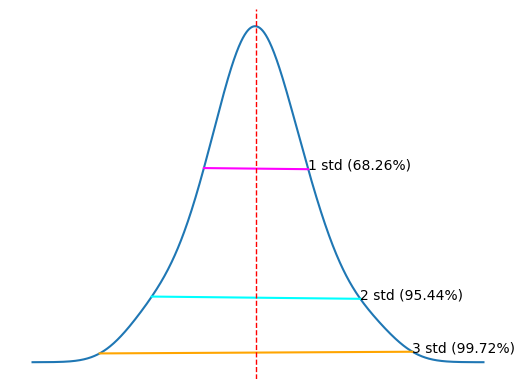

In [24]:
import scipy.stats as stats

col = df_students.Grade

density = stats.gaussian_kde(col)

col.plot.density()

s= col.std()
m = col.mean()

# First standard deviation
x1 = [m-s, m+s]
y1 = density(x1)
plt.plot(x1, y1, color='magenta')
plt.annotate('1 std (68.26%)', (x1[1],y1[1]))


# second standard deviation
x2 = [m-(s*2), m+(s*2)]
y2 = density(x2)
plt.plot(x2, y2, color='cyan')
plt.annotate('2 std (95.44%)', (x2[1],y2[1]))


# third standard deviation
x3 = [m-(s*3), m+(s*3)]
y3 = density(x3)
plt.plot(x3, y3, color='orange')
plt.annotate('3 std (99.72%)', (x3[1],y3[1]))


# Show the location of the mean
plt.axvline(col.mean(), color='red', linestyle='dashed', linewidth=1)
plt.axis('off')
plt.show()



In [25]:
df_students.describe()

,StudyHours,Grade
count,22.000000,22.000000
mean,10.522727,49.181818
std,3.487144,21.737912
min,1.000000,3.000000
25%,9.000000,36.250000
50%,10.000000,49.500000
75%,12.375000,62.750000
max,16.000000,97.000000


<Axes: title={'center': 'StudyHours'}, xlabel='Pass'>

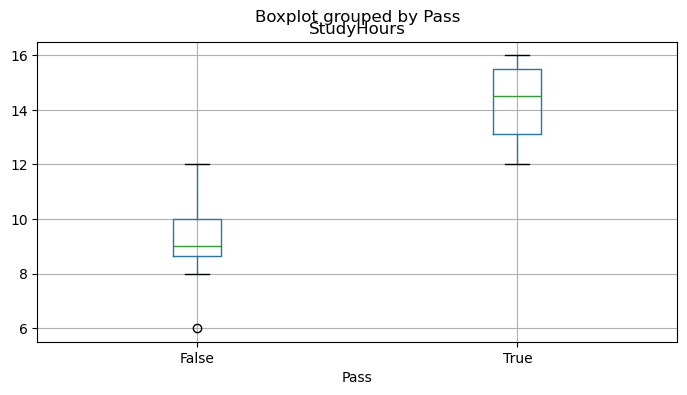

In [27]:
df_sample = df_students[df_students.StudyHours > 1]
df_sample.boxplot(column='StudyHours', by='Pass', figsize=(8, 4))


<Axes: xlabel='Name'>

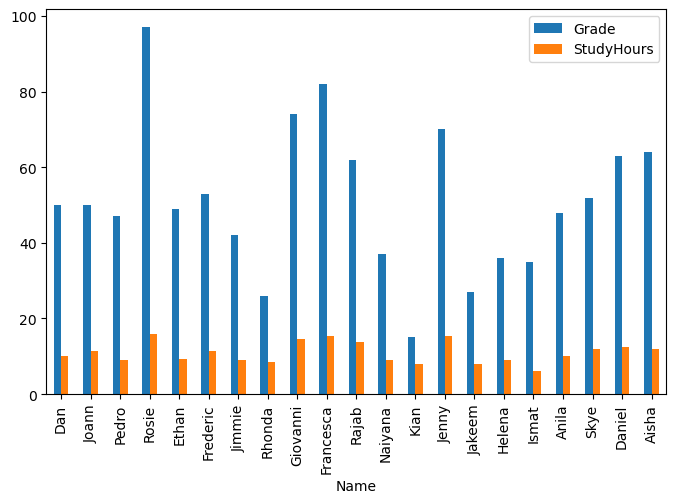

In [28]:
df_sample.plot(x='Name', y=['Grade', 'StudyHours'], kind='bar', figsize=(8,5))


<Axes: xlabel='Name'>

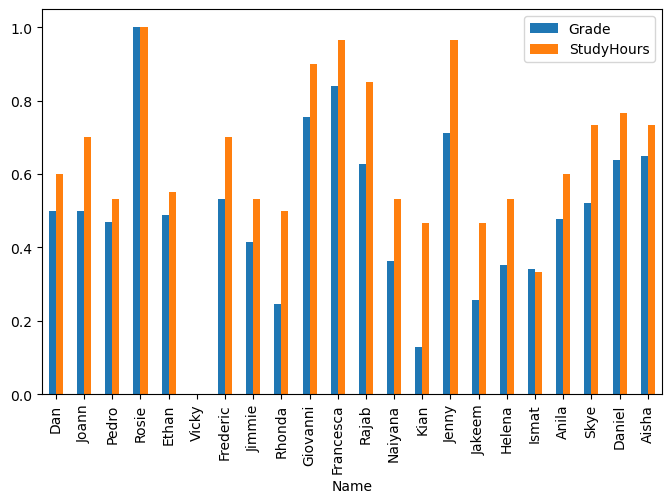

In [31]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_normalized = df_students.copy()

df_normalized[['Grade', 'StudyHours']] = scaler.fit_transform(df_normalized[['Grade', 'StudyHours']])

df_normalized.plot(x='Name', y=['Grade', 'StudyHours'], kind='bar', figsize=(8,5))

In [33]:
df_normalized.Grade.corr(df_normalized.StudyHours)

np.float64(0.9254280509006746)

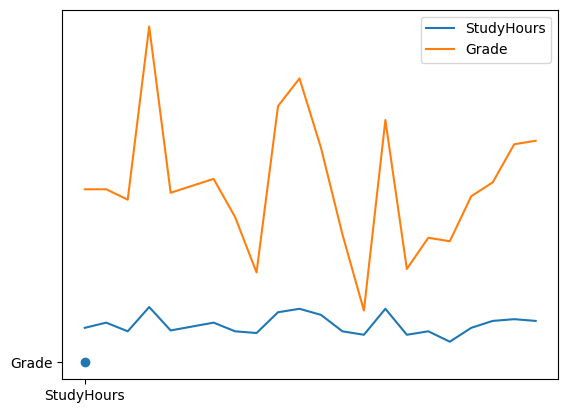

In [34]:
df_sample.plot().scatter(x='StudyHours', y='Grade')

Slope: 6.31342563379236
Intercept: -17.91640993281615
R-value: 0.9117666413789672
P-value: 8.912549627750964e-09
Standard Error: 0.6524367493101337


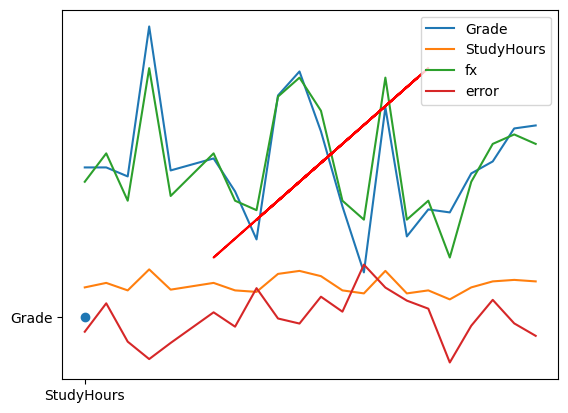

In [36]:
from scipy import stats
df_regression = df_sample[['Grade', 'StudyHours']].copy()

m, b, r, p, se = stats.linregress(df_regression.StudyHours, df_regression.Grade)

print(f'Slope: {m}\nIntercept: {b}\nR-value: {r}\nP-value: {p}\nStandard Error: {se}')

df_regression['fx'] = (m * df_regression.StudyHours) + b

df_regression['error'] = df_regression['fx'] - df_regression['Grade']

df_regression.plot().scatter(x='StudyHours', y='Grade')

# Plot regression line 
plt.plot(df_regression.StudyHours, df_regression.fx, color='red')
plt.show()


In [38]:
# Using regression coefficient for prediction

def f(x):
    m = 6.3134
    b = -17.964
    return (m * x) + b

study_hours = 14
predicted_grade = f(study_hours)

expected_grade = max(0, min(100, predicted_grade))

print(f'Predicted grade for {study_hours} study hours is {expected_grade}')    

Predicted grade for 14 study hours is 70.4236
